# Gene-panel diagnostic classifier (CatBoost / XGBoost)

Original Colab analysis. For the reusable version see `src/diagnostic_model.py`. Data paths point to Google Drive and must be changed to `data/`.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc, precision_recall_curve
)
from sklearn.preprocessing import StandardScaler
!pip install catboost xgboost scikit-optimize
from catboost import CatBoostClassifier
import xgboost as xgb
import shap

# Imports for Bayesian hyperparameter search
from skopt import BayesSearchCV
from skopt.space import Real, Integer
from sklearn.decomposition import PCA
import altair as alt
from skopt.utils import use_named_args
from tqdm import tqdm
from sklearn.model_selection import KFold


In [8]:

expression_matrix = pd.read_csv("/content/drive/MyDrive/random/islam/expression_matrix..csv", index_col=0)
labels = pd.read_csv("/content/drive/MyDrive/random/islam/labels.csv", index_col=0)



In [9]:
with open("/content/drive/MyDrive/random/islam/expression_matrix..csv", 'r') as f:
    for _ in range(5):
        print(f.readline())

with open("/content/drive/MyDrive/random/islam/labels.csv", 'r') as f:
    for _ in range(5):
        print(f.readline())


"A1BG","A1BG-AS1","A1CF","A2M","A2M-AS1","A2ML1","A2MP1","A4GALT","A4GNT","AA06","AAAS","AACS","AACSP1","AADAC","AADACL2","AADACP1","AADAT","AAGAB","AAK1","AAMDC","AAMP","AANAT","AAR2","AARS1","AARS2","AARSD1","AASDH","AASDHPPT","AASS","AATBC","AATF","AATK","ABAT","ABCA1","ABCA11P","ABCA12","ABCA13","ABCA17P","ABCA2","ABCA3","ABCA4","ABCA5","ABCA6","ABCA7","ABCA8","ABCA9","ABCB1","ABCB10","ABCB11","ABCB4","ABCB5","ABCB6","ABCB7","ABCB8","ABCB9","ABCC1","ABCC10","ABCC11","ABCC12","ABCC13","ABCC2","ABCC3","ABCC4","ABCC5","ABCC6","ABCC6P1","ABCC8","ABCC9","ABCD1","ABCD2","ABCD3","ABCD4","ABCE1","ABCF1","ABCF2","ABCF2-H2BK1","ABCF3","ABCG1","ABCG2","ABCG4","ABCG5","ABCG8","ABHD1","ABHD10","ABHD11","ABHD12","ABHD12B","ABHD13","ABHD14A","ABHD14B","ABHD15","ABHD16A","ABHD16B","ABHD17A","ABHD17B","ABHD17C","ABHD18","ABHD2","ABHD3","ABHD4","ABHD5","ABHD6","ABHD8","ABI1","ABI2","ABI3","ABI3BP","ABITRAM","ABL1","ABL2","ABLIM1","ABLIM2","ABLIM3","ABO","ABR","ABRA","ABRACL","ABRAXAS1","ABRAXAS2","A

In [10]:
print("Expression Matrix:")
print(expression_matrix.head())

print("\nLabels DataFr0ame:")
print(labels.head())


Expression Matrix:
                                           A1BG  A1BG-AS1       A1CF  \
GSM1523329_JZN_0469N_U133_2.CEL.gz    12.721545  4.824962  11.678591   
GSM1523330_JZN_0562N_U133_2.CEL.gz    12.472428  4.786868  11.428128   
GSM1523331_JZN_0591N_U133_2.CEL.gz    12.259287  4.894339  11.388907   
GSM1523332_JZN_0591N_U133_2.2.CEL.gz  12.244535  5.097471  11.388001   
GSM1523333_JZN_0591N_U133_2.3.CEL.gz  12.206660  5.463427  11.287127   

                                           A2M   A2M-AS1     A2ML1     A2MP1  \
GSM1523329_JZN_0469N_U133_2.CEL.gz    5.294720  4.354984  3.765654  4.466028   
GSM1523330_JZN_0562N_U133_2.CEL.gz    5.338120  4.527727  3.431057  4.370480   
GSM1523331_JZN_0591N_U133_2.CEL.gz    5.290557  4.048185  3.487159  4.455570   
GSM1523332_JZN_0591N_U133_2.2.CEL.gz  5.430716  4.220431  3.633610  3.980428   
GSM1523333_JZN_0591N_U133_2.3.CEL.gz  5.226731  4.610679  3.471941  4.119092   

                                        A4GALT     A4GNT      AA06 

In [11]:
# Optional: explicitly name the index to avoid confusion
labels.index.name = "SampleID"

# Normalize the index
labels.index = labels.index.astype(str).str.strip().str.upper()
expression_matrix.index = expression_matrix.index.astype(str).str.strip().str.upper()



In [12]:
# Align both datasets
common_ids = expression_matrix.index.intersection(labels.index)
expression_matrix = expression_matrix.loc[common_ids]
labels = labels.loc[common_ids]

# Final check
print("Filtered Expression Matrix Shape:", expression_matrix.shape)
print("Filtered Labels Shape:", labels.shape)


Filtered Expression Matrix Shape: (91, 21358)
Filtered Labels Shape: (91, 1)


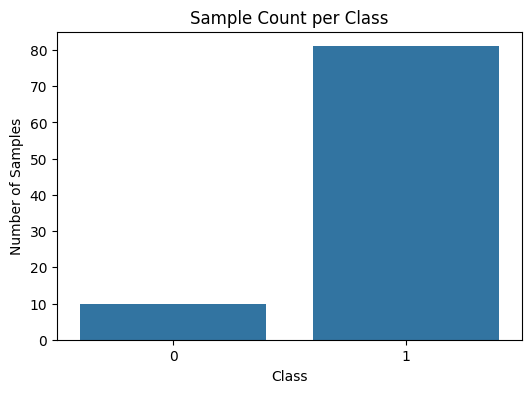

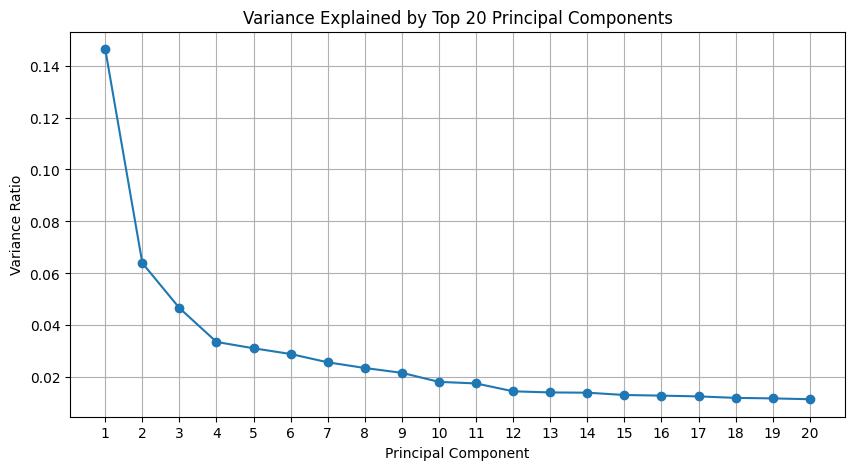

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import plotly.express as px

# Assuming expression_matrix and labels are already defined and aligned

# 1. Visualize Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=labels['Label'])
plt.title("Sample Count per Class")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()

# 2. PCA for 3D Visualization (Interactive with Plotly)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(expression_matrix)

pca = PCA(n_components=3)
pca_result = pca.fit_transform(scaled_data)

pca_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2', 'PC3'])
pca_df['Label'] = labels['Label'].values

# Add a 'SampleID' column to pca_df from the index of the original expression_matrix
# This assumes the index of expression_matrix holds your sample IDs
pca_df['SampleID'] = expression_matrix.index

fig = px.scatter_3d(
    pca_df, x='PC1', y='PC2', z='PC3', color=pca_df['Label'].astype(str),
    title='3D PCA of Gene Expression Data',
    labels={'color': 'Class'},
    hover_name='SampleID'  # Specify the column to show on hover
)
fig.update_layout(scene=dict(
    xaxis_title=f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)",
    yaxis_title=f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)",
    zaxis_title=f"PC3 ({pca.explained_variance_ratio_[2]*100:.1f}%)"
))
fig.show()
# 3. Plot of Variance Explained by Top Principal Components
pca_full = PCA()
pca_full.fit(scaled_data)
explained_variance = pca_full.explained_variance_ratio_

plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), explained_variance[:20], marker='o')
plt.title("Variance Explained by Top 20 Principal Components")
plt.xlabel("Principal Component")
plt.ylabel("Variance Ratio")
plt.xticks(range(1, 21))
plt.grid(True)
plt.show()


 Filtered Expression Matrix Shape: (91, 21358)
 Filtered Labels Shape: (91, 1)
 Starting CATBOOST Diagnostic Pipeline...
Sample 'GSM1523338_JZN_0934N_U133_2.3.CEL.GZ' successfully placed in the training set.

 Starting Bayesian hyperparameter search for CATBOOST...



  Best CATBOOST params: OrderedDict([('bagging_temperature', 0.621747191369693), ('depth', 10), ('l2_leaf_reg', 1.0), ('learning_rate', 0.01)])



 Gene Importance Ranking (CATBOOST):
       Gene  Importance
23  SLC16A4   13.165813
6       BAX   10.619428
16     ENO1    7.661770
2     SNAI1    5.437181
13      PKM    4.649531
20     TOP1    3.693817
5      TP53    3.467999
26    FGFR1    3.292887
10  ATP6V1H    3.095339
24     CCL2    3.009237

 Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.96      1.00      0.98        24

    accuracy                           0.96        27
   macro avg       0.98      0.83      0.89        27
weighted avg       0.96      0.96      0.96        27

 AUC Score: 1.0
 Confusion Matrix:
 [[ 2  1]
 [ 0 24]]


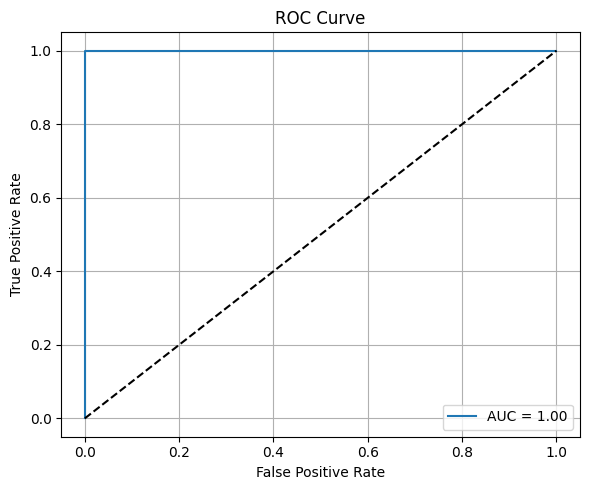

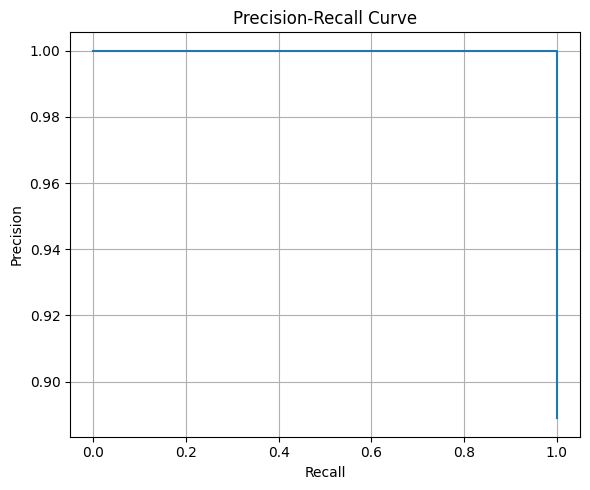

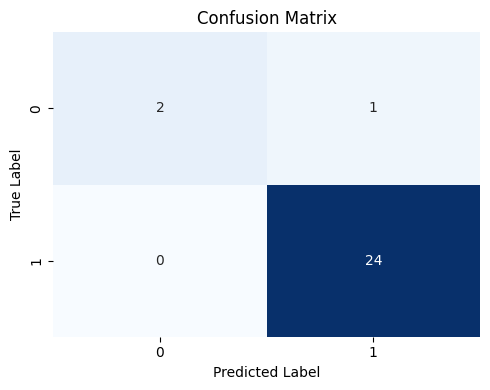


 Cross-Validation AUC Scores (CV=5):
   Mean AUC: 0.994 ± 0.013
   Individual folds: [1.      1.      1.      1.      0.96875]
 Generating SHAP explanations (CATBOOST)...


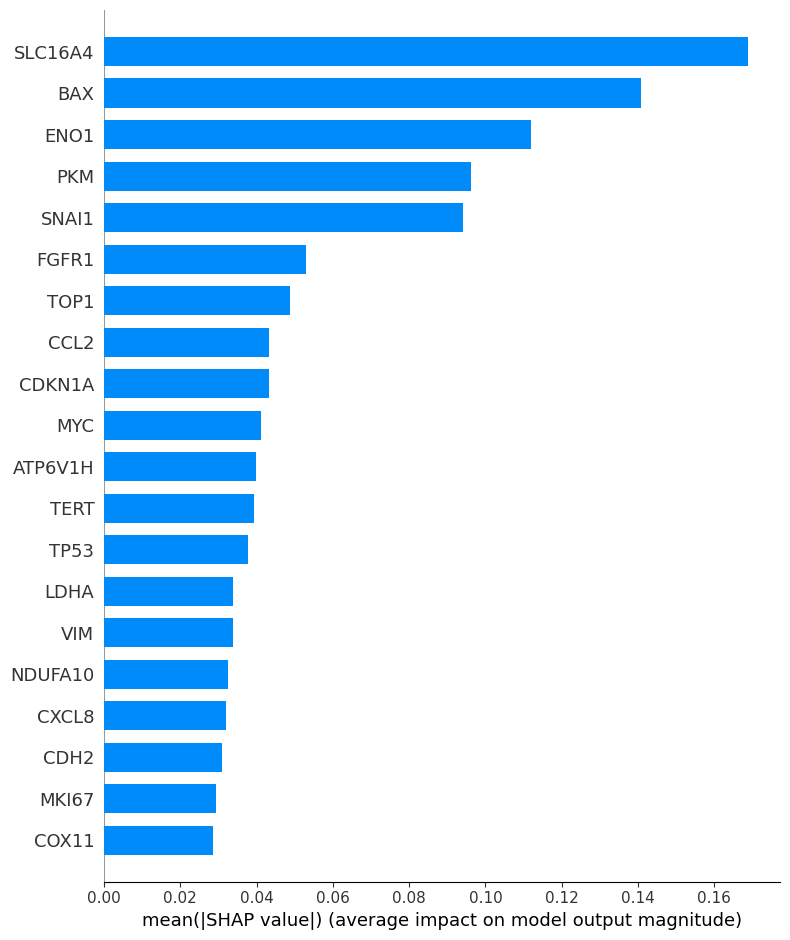

 Starting XGBOOST Diagnostic Pipeline...
Sample 'GSM1523338_JZN_0934N_U133_2.3.CEL.GZ' successfully placed in the training set.

 Starting Bayesian hyperparameter search for XGBOOST...



  Best XGBOOST params: OrderedDict([('colsample_bytree', 1.0), ('learning_rate', 0.1), ('max_depth', 8), ('reg_lambda', 1.0), ('subsample', 0.6)])

 Gene Importance Ranking (XGBOOST):
       Gene  Importance
13      PKM    0.194523
16     ENO1    0.185381
23  SLC16A4    0.128954
27    CXCL8    0.123340
6       BAX    0.120912
2     SNAI1    0.115029
26    FGFR1    0.041326
24     CCL2    0.035433
15     LDHA    0.033427
9     COX11    0.021673

 Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.67      0.80         3
           1       0.96      1.00      0.98        24

    accuracy                           0.96        27
   macro avg       0.98      0.83      0.89        27
weighted avg       0.96      0.96      0.96        27

 AUC Score: 1.0
 Confusion Matrix:
 [[ 2  1]
 [ 0 24]]


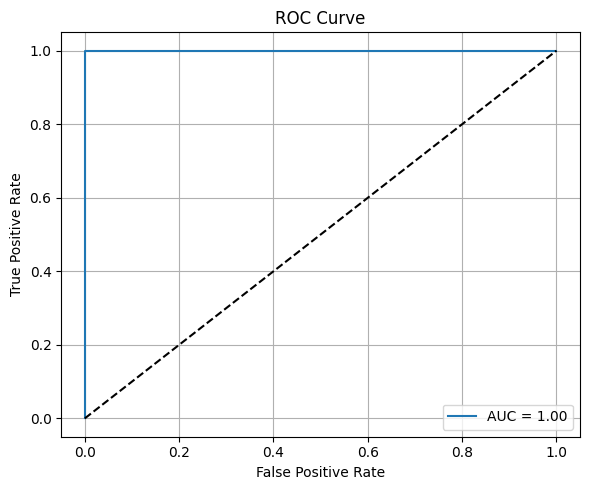

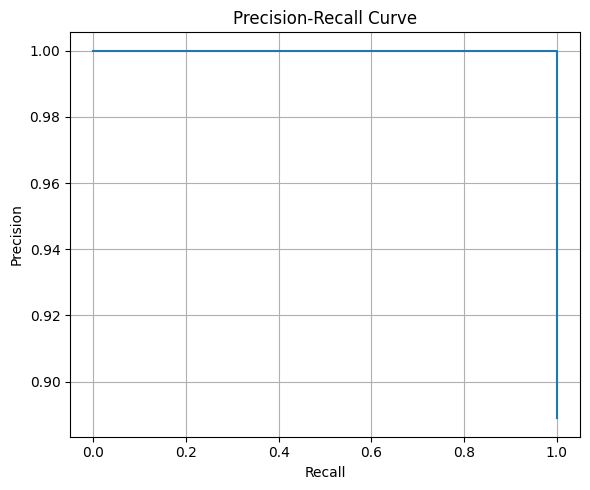

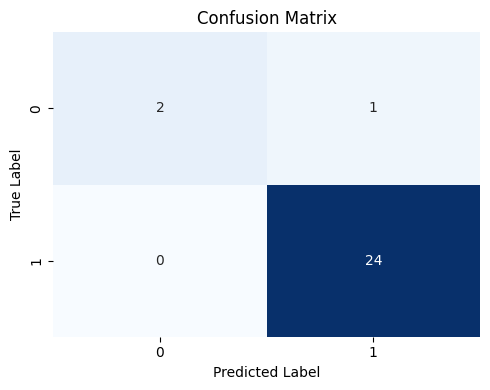


 Cross-Validation AUC Scores (CV=5):
   Mean AUC: 0.981 ± 0.025
   Individual folds: [1.      1.      1.      0.96875 0.9375 ]
 Generating SHAP explanations (XGBOOST)...


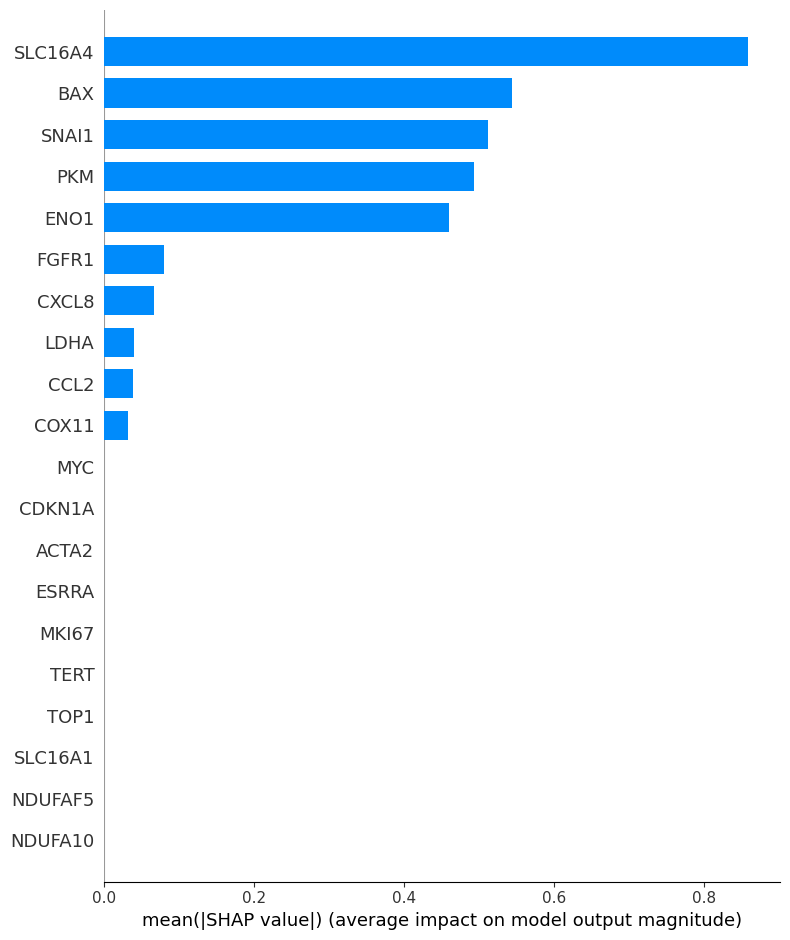


=== Model AUC Comparison ===
CatBoost AUC:   1.000
XGBoost AUC:    1.000


In [32]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, roc_curve, auc, precision_recall_curve
from catboost import CatBoostClassifier
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from skopt import BayesSearchCV
from skopt.space import Real, Integer
from tqdm import tqdm
import shap # Make sure you have shap installed

class DiagnosticModel:
    def __init__(self, expression_matrix, labels, model_type='catboost'):
        self.target_genes = [
            "CDH1", "CDH2", "SNAI1", "SNAI2", "VIM", "TP53", "BAX", "BCL2", "CASP3",
            "COX11", "ATP6V1H", "NDUFAF5", "NDUFA10", "PKM", "TPI1", "LDHA", "ENO1",
            "ESRRA", "MKI67", "TERT", "TOP1", "CDKN1A", "SLC16A1", "SLC16A4",
            "CCL2", "MYC", "FGFR1", "CXCL8", "ACTA2"
        ]
        self.available_genes = [gene for gene in self.target_genes if gene in expression_matrix.columns]
        self.model_type = model_type

        if len(self.available_genes) < 5:
            raise ValueError("Too few target genes found in expression matrix.")

        self.X = expression_matrix[self.available_genes]
        self.y = labels.values.ravel()

        # Base model with fixed boosting rounds = 150
        if model_type == 'catboost':
            self.model = CatBoostClassifier(
                iterations=150,
                verbose=0,
                random_seed=42
            )
        elif model_type == 'xgboost':
            self.model = xgb.XGBClassifier(
                n_estimators=150,
                random_state=42,
                eval_metric='logloss',
                use_label_encoder=False,
                verbosity=0
            )
        else:
            raise ValueError("Invalid model_type. Choose 'catboost' or 'xgboost'")

        self.explainer = None
        self.shap_values = None

    def preprocess(self, test_size=0.3, random_state=42, sample_to_train=''):
        """
        Preprocesses the data by splitting it into training and testing sets.

        Args:
            test_size (float): The proportion of the dataset to include in the test split.
            random_state (int): Controls the shuffling applied to the data before applying the split.
            sample_to_train (str): The ID of a specific sample to ensure it's in the training set.
        """
        if sample_to_train:
            # Check if the specified sample exists in the data
            if sample_to_train not in self.X.index:
                print(f"Warning: Sample '{sample_to_train}' not found in the dataset. Proceeding with standard split.")
                self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
                    self.X, self.y,
                    test_size=test_size,
                    random_state=random_state,
                    stratify=self.y
                )
            else:
                # Isolate the sample to be in the training set
                train_specific_sample_X = self.X.loc[[sample_to_train]]
                train_specific_sample_y = self.y[self.X.index == sample_to_train]

                # Create the remaining dataset (excluding the specific sample)
                remaining_X = self.X.drop(index=sample_to_train)
                remaining_y_indices = self.X.index != sample_to_train
                remaining_y = self.y[remaining_y_indices]

                # Perform train-test split on the remaining data
                X_train_remaining, self.X_test, y_train_remaining, self.y_test = train_test_split(
                    remaining_X, remaining_y,
                    test_size=test_size,
                    random_state=random_state,
                    stratify=remaining_y
                )

                # Combine the specific sample with the training set
                self.X_train = pd.concat([train_specific_sample_X, X_train_remaining])
                self.y_train = pd.concat([pd.Series(train_specific_sample_y, index=train_specific_sample_X.index), pd.Series(y_train_remaining, index=X_train_remaining.index)]).values

                print(f"Sample '{sample_to_train}' successfully placed in the training set.")
        else:
            # Standard train_test_split if no specific sample is requested
            self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
                self.X, self.y,
                test_size=test_size,
                random_state=random_state,
                stratify=self.y
            )

    def _tune_hyperparameters(self):
      total_iterations = 60

      if self.model_type == 'catboost':
          search_space = {
              'depth': Integer(4, 10),
              'learning_rate': Real(0.01, 0.1, prior='log-uniform'),
              'l2_leaf_reg': Real(1, 10, prior='log-uniform'),
              'bagging_temperature': Real(0.5, 2.0)
          }

      elif self.model_type == 'xgboost':
          search_space = {
              'max_depth': Integer(3, 9),
              'learning_rate': Real(0.01, 0.1, prior='log-uniform'),
              'subsample': Real(0.6, 1.0),
              'colsample_bytree': Real(0.6, 1.0),
              'reg_lambda': Real(1, 10, prior='log-uniform')
          }

      else:
          raise ValueError("Invalid model_type. Choose 'catboost' or 'xgboost'")

      pbar = tqdm(total=total_iterations, desc="Tuning Hyperparameters")
      def update_pbar(res):
          pbar.update(1)


      bayes_search = BayesSearchCV(
        estimator=self.model,
        search_spaces=search_space,
        n_iter=total_iterations,
        scoring='roc_auc',
        cv=5,
        n_jobs=-1,
        random_state=18,
        optimizer_kwargs={'n_initial_points': 20},
        verbose=0  # SUPPRESS MESSAGES HERE
        # Remove callback from here
      )

      # Pass the callback to the fit method
      bayes_search.fit(self.X_train, self.y_train, callback=[update_pbar])
      self.model = bayes_search.best_estimator_

      print(f"\n  Best {self.model_type.upper()} params: {bayes_search.best_params_}")
    def train(self, tune=True):
        # If tune=True, perform Bayesian hyperparameter tuning first
        if tune:
            print(f"\n Starting Bayesian hyperparameter search for {self.model_type.upper()}...")
            self._tune_hyperparameters()

        # Fit the (possibly tuned) model on training data
        self.model.fit(self.X_train, self.y_train)

        # Feature importances
        if self.model_type == 'catboost':
            importances = self.model.get_feature_importance()
        elif self.model_type == 'xgboost':
            importances = self.model.feature_importances_

        importance_df = pd.DataFrame({
            'Gene': self.X_train.columns,
            'Importance': importances
        }).sort_values('Importance', ascending=False)

        print(f"\n Gene Importance Ranking ({self.model_type.upper()}):")
        print(importance_df.head(10))

    def evaluate(self):
        y_pred = self.model.predict(self.X_test)
        y_prob = self.model.predict_proba(self.X_test)[:, 1]

        print("\n Classification Report:\n", classification_report(self.y_test, y_pred))
        print(" AUC Score:", roc_auc_score(self.y_test, y_prob))
        print(" Confusion Matrix:\n", confusion_matrix(self.y_test, y_pred))

        self._plot_roc_curve(y_prob)
        self._plot_precision_recall_curve(y_prob)
        self._plot_confusion_matrix(y_pred)

    def _plot_roc_curve(self, y_prob):
        fpr, tpr, _ = roc_curve(self.y_test, y_prob)
        roc_auc = auc(fpr, tpr)

        plt.figure(figsize=(6, 5))
        plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
        plt.plot([0, 1], [0, 1], 'k--')
        plt.xlabel('False Positive Rate')
        plt.ylabel('True Positive Rate')
        plt.title('ROC Curve')
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    def _plot_precision_recall_curve(self, y_prob):
        precision, recall, _ = precision_recall_curve(self.y_test, y_prob)

        plt.figure(figsize=(6, 5))
        plt.plot(recall, precision)
        plt.xlabel('Recall')
        plt.ylabel('Precision')
        plt.title('Precision-Recall Curve')
        plt.grid(True)
        plt.tight_layout()
        plt.show()

    def explain_model(self, max_display=20):
        print(f" Generating SHAP explanations ({self.model_type.upper()})...")
        self.explainer = shap.TreeExplainer(self.model)

        if self.model_type == 'catboost':
            self.shap_values = self.explainer.shap_values(self.X_train)
        elif self.model_type == 'xgboost':
            self.shap_values = self.explainer(self.X_train)

        shap.summary_plot(
            self.shap_values,
            self.X_train,
            plot_type='bar',
            max_display=max_display
        )

    def cross_validate(self, cv=5):
        cv_scores = cross_val_score(self.model, self.X, self.y, cv=cv, scoring='roc_auc')
        print(f"\n Cross-Validation AUC Scores (CV={cv}):")
        print(f"   Mean AUC: {cv_scores.mean():.3f} ± {cv_scores.std():.3f}")
        print(f"   Individual folds: {cv_scores}")

    def classify_new_samples(self, new_samples):
        available = [gene for gene in self.available_genes if gene in new_samples.columns]
        missing = set(self.available_genes) - set(available)

        if missing:
            print(f" Warning: Missing {len(missing)} genes in new samples.")

        preds = self.model.predict(new_samples[available])
        probs = self.model.predict_proba(new_samples[available])[:, 1]

        return pd.DataFrame({
            'Sample_ID': new_samples.index,
            'Predicted_Class': preds,
            'Probability': probs
        })

    def run_full_pipeline(self, tune=True, sample_to_train=''):
        print(f" Starting {self.model_type.upper()} Diagnostic Pipeline...")
        self.preprocess(sample_to_train=sample_to_train) # Pass the sample_to_train argument
        self.train(tune=tune)
        self.evaluate()
        self.cross_validate()
        self.explain_model()

    def _plot_confusion_matrix(self, y_pred):
        cm = confusion_matrix(self.y_test, y_pred)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.title('Confusion Matrix')
        plt.tight_layout()
        plt.show()


def main():
    import pandas as pd
    from sklearn.metrics import roc_auc_score
    from datetime import datetime

    # Load expression matrix and labels (update paths as needed)
    expression_matrix = pd.read_csv(
        "/content/drive/MyDrive/random/islam/expression_matrix..csv",
        index_col=0
    )
    expression_matrix.columns = expression_matrix.columns.str.split('.').str[0]
    labels = pd.read_csv(
        "/content/drive/MyDrive/random/islam/labels.csv",
        index_col=0
    )

    # Optional: explicitly name the index to avoid confusion
    labels.index.name = "SampleID"

    # Normalize the index
    labels.index = labels.index.astype(str).str.strip().str.upper()
    expression_matrix.index = expression_matrix.index.astype(str).str.strip().str.upper()

    # Align both datasets
    common_ids = expression_matrix.index.intersection(labels.index)
    expression_matrix = expression_matrix.loc[common_ids]
    labels = labels.loc[common_ids]

    print(f" Filtered Expression Matrix Shape: {expression_matrix.shape}")
    print(f" Filtered Labels Shape: {labels.shape}")

    # Helper to save model summary info
    def save_model_info(model, model_type, auc_score, feature_list, sample_count, info_filename):
        timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        info = f"""# Diagnostic Model Summary ({model_type.upper()})

Timestamp: {timestamp}

AUC Score (Test Set): {auc_score:.3f}
Number of Samples: {sample_count}
Genes Used ({len(feature_list)}): {', '.join(feature_list)}

Output Files:
- `{model_type}_predictions.csv`: Predicted class and probability for each sample
- `{model_type}_model.{ 'cbm' if model_type=='catboost' else 'json' }`: Saved {model_type.upper()} model
"""
        with open(info_filename, "w") as f:
            f.write(info)

    # Define the specific sample ID to be in the training set
    specific_sample_id = "GSM1523338_JZN_0934N_U133_2.3.CEL.GZ"

    # -------------------------
    # 1. Train & Evaluate CatBoost (with Bayesian tuning)
    # -------------------------
    cat_model = DiagnosticModel(
        expression_matrix,
        labels,
        model_type="catboost"
    )
    cat_model.run_full_pipeline(sample_to_train=specific_sample_id) # Pass the sample_to_train

    # Compute CatBoost AUC on test set
    cat_y_true = cat_model.y_test
    cat_y_prob = cat_model.model.predict_proba(cat_model.X_test)[:, 1]
    cat_auc = roc_auc_score(cat_y_true, cat_y_prob)

    # Save CatBoost predictions & model
    cat_predictions = cat_model.classify_new_samples(expression_matrix)
    cat_predictions.to_csv("catboost_predictions.csv", index=False)
    cat_model.model.save_model("catboost_model.cbm")

    # Save CatBoost info summary
    save_model_info(
        model=cat_model,
        model_type="catboost",
        auc_score=cat_auc,
        feature_list=cat_model.available_genes,
        sample_count=expression_matrix.shape[0],
        info_filename="catboost_model_info.txt"
    )

    # -------------------------
    # 2. Train & Evaluate XGBoost (with Bayesian tuning)
    # -------------------------
    xgb_model = DiagnosticModel(
        expression_matrix,
        labels,
        model_type="xgboost"
    )
    xgb_model.run_full_pipeline(sample_to_train=specific_sample_id) # Pass the sample_to_train

    # Compute XGBoost AUC on test set
    xgb_y_true = xgb_model.y_test
    xgb_y_prob = xgb_model.model.predict_proba(xgb_model.X_test)[:, 1]
    xgb_auc = roc_auc_score(xgb_y_true, xgb_y_prob)

    # Save XGBoost predictions & model
    xgb_predictions = xgb_model.classify_new_samples(expression_matrix)
    xgb_predictions.to_csv("xgboost_predictions.csv", index=False)
    xgb_model.model.save_model("xgboost_model.json")

    # Save XGBoost info summary
    save_model_info(
        model=xgb_model,
        model_type="xgboost",
        auc_score=xgb_auc,
        feature_list=xgb_model.available_genes,
        sample_count=expression_matrix.shape[0],
        info_filename="xgboost_model_info.txt"
    )

    # -------------------------
    # 3. Print AUC Comparison
    # -------------------------
    print("\n=== Model AUC Comparison ===")
    print(f"CatBoost AUC:   {cat_auc:.3f}")
    print(f"XGBoost AUC:    {xgb_auc:.3f}")

    return (cat_model, xgb_model), (cat_predictions, xgb_predictions)


if __name__ == "__main__":
    (cat_model_inst, xgb_model_inst), (cat_preds_df, xgb_preds_df) = main()